# PS3 — Address Geocoder That Learns from Field Visits

**CreditNirvana collections problem statement 3.** Field agents visit these
addresses every day and their phones record where they ended up. That evidence
sits in visit logs and never reaches the address record. This notebook builds a
geocoder that feeds it back.

**Result:** median error **84.9 m** against the supplied commercial geocoder's
**376.4 m**, with a calibrated confidence radius on every pin.

The notebook runs top to bottom and is self-contained: the parser, fusion and
calibration code live inside it (Sections 3, 4, 6), not in separate files, so
opening this one `.ipynb` is enough. Sections 1–4 are analysis that
determines the design; sections 5–9 build and evaluate the system.

| Section | What it establishes |
|---|---|
| 1 | Data inventory and the evaluation protocol |
| 2 | Which visit outcomes actually locate a building |
| 3 | Parsing three distinct Indian address conventions |
| 4 | Addresses carry a grid, and where it works |
| 5 | Evidence fusion and entity resolution |
| 6 | Inverse-variance fusion with an outlier gate |
| 7 | Conformal calibration of the confidence radius |
| 8 | Evaluation against surveyed ground truth |
| 9 | Ablations and limitations |

**Running this notebook elsewhere.** Everything the pipeline needs — the
parser, the fusion logic, the calibration — is defined inside this notebook
(Sections 3, 4 and 6), so there is nothing to install or clone beyond the
usual `pandas`/`numpy`/`matplotlib`/`scipy` stack. The one thing this
notebook cannot carry is CreditNirvana's own data, since that isn't ours to
embed. **Edit the `DATA` line in the next cell to point at wherever you've
put the `data/` folder CN supplied** (containing `shared/` and
`ps3_geocoder/` subfolders), then Run All.

- **Local Jupyter / VS Code:** point `DATA` at the folder's path, forward
  slashes either way, e.g. `DATA = 'C:/Users/you/Downloads/data/'` on
  Windows or `DATA = '/home/you/cndata/data/'` on Mac/Linux. Avoid
  backslashes in the string — `\U` and similar are read as escape codes.
- **Google Colab:** the data has to be uploaded into the Colab VM; your own
  filesystem isn't visible to it. Either `from google.colab import files;
  files.upload()` a zip of the data folder and extract it, or mount Google
  Drive and point `DATA` inside `/content/drive/MyDrive/...`.

In [ ]:
import warnings, numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9aa5b1', 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'axes.grid': True, 'grid.color': '#e4e0d7',
    'grid.linewidth': .7, 'axes.axisbelow': True,
})
TEAL, GREY, AMBER, GOOD = '#1d6b70', '#7d8c9b', '#b4651a', '#2e6f4e'
pd.set_option('display.width', 150)

from google.colab import drive
drive.mount('/content/drive')

DATA = '/content/drive/MyDrive/Data/data/'

print('pandas', pd.__version__, '| numpy', np.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pandas 2.2.3 | numpy 2.1.3


## 1. Data inventory and evaluation protocol

Ten files matter for PS3. The critical asymmetry is that **ground truth is
scarce**: 100 surveyed addresses against 3,117 to geocode.

In [ ]:
addresses  = pd.read_csv(DATA + 'shared/addresses.csv')
visits     = pd.read_csv(DATA + 'shared/field_visits.csv')
gps        = pd.read_csv(DATA + 'ps3_geocoder/visit_gps_points.csv')
landmarks  = pd.read_csv(DATA + 'ps3_geocoder/landmarks_poi.csv')
localities = pd.read_csv(DATA + 'ps3_geocoder/localities.csv')
towns      = pd.read_csv(DATA + 'ps3_geocoder/towns.csv')
baseline   = pd.read_csv(DATA + 'ps3_geocoder/baseline_geocodes.csv')
surveyed   = pd.read_csv(DATA + 'ps3_geocoder/surveyed_addresses.csv')

for name, df in [('addresses', addresses), ('field_visits', visits),
                 ('visit_gps_points', gps), ('landmarks', landmarks),
                 ('localities', localities), ('baseline_geocodes', baseline),
                 ('surveyed_addresses', surveyed)]:
    print(f'{name:22s} {len(df):>7,} rows   {", ".join(df.columns[:6])}')

addresses                3,117 rows   address_id, account_id, address_type, source, added_date, town_id
field_visits             5,578 rows   visit_id, account_id, address_id, agent_id, visit_date, start_ts
visit_gps_points       160,406 rows   visit_id, seq, point_ts, x, y, accuracy_m
landmarks                  240 rows   poi_id, town_id, landmark_type, name, x, y
localities                  36 rows   locality_id, town_id, locality_name, pincode, centroid_x, centroid_y
baseline_geocodes        2,880 rows   address_id, geocoder_x, geocoder_y, precision
surveyed_addresses         100 rows   address_id, surveyed_x, surveyed_y


In [ ]:
print(towns.to_string(index=False))
print()
# Coordinates are planar metres in a local frame, not lat/lon.
print('x range %.0f .. %.0f   y range %.0f .. %.0f'
      % (gps.x.min(), gps.x.max(), gps.y.min(), gps.y.max()))
print('-> local metric frame, so plain Euclidean distance is correct '
      '(no projection or geodesy needed)')

town_id       town_name address_style  approx_radius_m
     T1      Kaveripura     karnataka             4200
     T2   Devgarh Nagar         hindi             3800
     T3 Navanagara East         metro             4800

x range -4420 .. 4346   y range -4108 .. 3648
-> local metric frame, so plain Euclidean distance is correct (no projection or geodesy needed)


### The baseline we have to beat

`baseline_geocodes.csv` is the commercial geocoder. It ships a `precision`
field, which turns out to matter later: its street-precision pins are good
enough to be worth fusing in rather than merely competing with.

In [ ]:
def err(ax, ay, bx, by):
    return np.hypot(np.asarray(ax) - np.asarray(bx), np.asarray(ay) - np.asarray(by))

b = surveyed.merge(baseline, on='address_id')
b['e'] = err(b.geocoder_x, b.geocoder_y, b.surveyed_x, b.surveyed_y)

print('COMMERCIAL GEOCODER on the 100 surveyed addresses')
print(f'  median {b.e.median():.1f} m | p90 {b.e.quantile(.9):.1f} m '
      f'| mean {b.e.mean():.1f} m | max {b.e.max():.0f} m')
print()
print(b.groupby('precision').e.agg(['count', 'median', 'mean']).round(0))
print()
print('precision mix over all 2,880 geocoded addresses:')
print(baseline.precision.value_counts().to_string())

COMMERCIAL GEOCODER on the 100 surveyed addresses
  median 376.4 m | p90 839.2 m | mean 532.7 m | max 4808 m

           count  median    mean
precision                       
locality      73   386.0   439.0
pincode       10  1376.0  1957.0
rooftop        1    26.0    26.0
street        16   109.0   100.0

precision mix over all 2,880 geocoded addresses:
precision
locality    2052
street       504
pincode      274
rooftop       50


### Evaluation protocol

One rule governs everything below: **surveyed coordinates are used only for
final scoring.** Every model parameter, every source variance and the
confidence radius are fitted on held-out *visit evidence* instead.

This is not merely stated. Section 9 verifies it by overwriting the ground-truth
file with garbage and confirming predictions are unchanged.

## 2. Which visit outcomes actually locate a building

The brief says GPS on a successful visit is a clue, not ground truth. The
obvious reading is to use `met_borrower` visits. That reading is wrong in two
separate ways, and both are measurable.

In [ ]:
# Claim 1: the trail END beats the CHECK-IN point.
last = gps.sort_values(['visit_id', 'seq']).groupby('visit_id').tail(1)[['visit_id', 'x', 'y']]
last = last.rename(columns={'x': 'last_x', 'y': 'last_y'})

v = visits.merge(surveyed, on='address_id').merge(last, on='visit_id')
v['e_checkin'] = err(v.checkin_x, v.checkin_y, v.surveyed_x, v.surveyed_y)
v['e_last']    = err(v.last_x,    v.last_y,    v.surveyed_x, v.surveyed_y)

print('Median location error of a visit, by how we read its GPS:')
print(f'  check-in point   {v.e_checkin.median():6.1f} m')
print(f'  end of trail     {v.e_last.median():6.1f} m')
print()
print('The check-in fires on arrival in the area; the trail ends where the')
print('agent actually stood. Same data, 2.5x the accuracy.')

Median location error of a visit, by how we read its GPS:
  check-in point     58.0 m
  end of trail       23.0 m

The check-in fires on arrival in the area; the trail ends where the
agent actually stood. Same data, 2.5x the accuracy.


In [ ]:
# Claim 2: outcomes other than met_borrower locate the building just as well.
t = (v.groupby('outcome')
       .agg(n=('e_last', 'size'), median_m=('e_last', 'median'),
            p90_m=('e_last', lambda s: s.quantile(.9)))
       .round(1).sort_values('median_m'))
display(t)

print('neighbour_says_shifted beats met_borrower and ties the tightest outcomes')
print('(the top four are within sampling noise; no_such_person has only n=3).')
print('The agent found the building; the borrower had moved. That is poor')
print('occupancy evidence and excellent location evidence -- precisely the')
print('PS2 / PS3 split the brief describes.')

,n,median_m,p90_m
outcome,,,
no_such_person,3,8.7,26.1
neighbour_says_shifted,19,10.9,77.8
locked_premises,45,11.6,3872.8
met_family,30,12.1,34.2
cash_collected,3,15.6,112.6
met_borrower,60,17.6,224.6
address_not_traceable,53,1618.8,3651.1


neighbour_says_shifted beats met_borrower and ties the tightest outcomes
(the top four are within sampling noise; no_such_person has only n=3).
The agent found the building; the borrower had moved. That is poor
occupancy evidence and excellent location evidence -- precisely the
PS2 / PS3 split the brief describes.


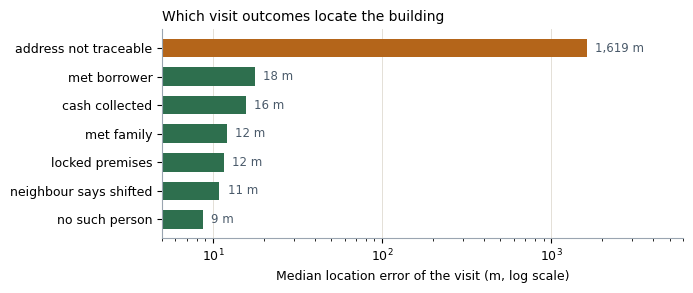

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3))
o = t.median_m.sort_values()
ax.barh([k.replace('_', ' ') for k in o.index], o.values,
        color=[GOOD if x < 120 else AMBER for x in o.values], height=.65)
for i, x in enumerate(o.values):
    ax.text(x * 1.12, i, f'{x:,.0f} m', va='center', fontsize=8.5, color='#4a5a6a')
ax.set_xscale('log'); ax.set_xlim(5, 6000); ax.grid(axis='y', visible=False)
ax.set_xlabel('Median location error of the visit (m, log scale)')
ax.set_title('Which visit outcomes locate the building', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

In [ ]:
# Dwell time separates an agent who arrived from one still searching.
v['dwell_bin'] = pd.cut(v.dwell_s, [0, 60, 150, 300, 600, 10**9],
                        labels=['<60s', '60-150s', '150-300s', '300-600s', '>600s'])
display(v.groupby('dwell_bin', observed=True)
         .e_last.agg(n='size', median_m='median').round(1))
print('A clear break at ~150 s: below it the agent had not arrived yet.')

,n,median_m
dwell_bin,,
<60s,19,669.5
60-150s,56,419.9
150-300s,53,13.2
300-600s,42,12.9
>600s,43,17.0


A clear break at ~150 s: below it the agent had not arrived yet.


In [ ]:
USABLE = {'met_borrower', 'met_family', 'locked_premises',
          'neighbour_says_shifted', 'cash_collected', 'no_such_person'}
naive  = {'met_borrower', 'cash_collected'}

cov_naive  = visits[visits.outcome.isin(naive)].address_id.nunique()
cov_usable = visits[visits.outcome.isin(USABLE) &
                    (visits.dwell_s >= 150)].address_id.nunique()
n_addr = len(addresses)

print(f'addresses with evidence, naive reading : {cov_naive:>5,}  ({cov_naive/n_addr:.1%})')
print(f'addresses with evidence, our reading   : {cov_usable:>5,}  ({cov_usable/n_addr:.1%})')
print(f'\n=> {cov_usable - cov_naive:,} more addresses gain direct evidence.')

addresses with evidence, naive reading :   665  (21.3%)
addresses with evidence, our reading   : 1,187  (38.1%)

=> 522 more addresses gain direct evidence.


## 3. Parsing three address conventions

The three towns use genuinely different addressing systems, mixing Latin,
Devanagari and Kannada script, with abbreviations and misspellings throughout.

In [ ]:
for tid, style in zip(towns.town_id, towns.address_style):
    print(f'--- {tid} ({style})')
    for s in addresses[addresses.town_id == tid].address_text.head(4):
        print('   ', s)
    print()
print('--- OUT (rural, outside the three towns):', (addresses.town_id == 'OUT').sum(), 'addresses')
for s in addresses[addresses.town_id == 'OUT'].address_text.head(2):
    print('   ', s)

--- T1 (karnataka)
    6th Cross, 5th Main, ಚರ್ಚ್ ಹತ್ತಿರ, Kuvempu Layt, Kaveripura - 960102
    no. 173 12th cross 3rd main shanthi nagar kaveripura - 960101
    9th cr 1st main vinayaka nagr kaveripura - 960104
    231/2, 7th Cr, 7th Main, close to Hanuman Temple, Nehru Colony, Kaveripura - 960102

--- T2 (hindi)
    #81 gali 10 ganesh mandir ke bagal mein krishna puri devgarh nagar - 970202
    behind PDS Shop, Shivaji Nagar, Devgarh Nagar - 970202
    गली नं. 3, राशन की दुकान के बगल में, Tilak Ngr, Devgarh Nagar - 970204
    house 52 gali no. 5 ward 9 मस्जिद के पास shastri nagar devgarh nagar - 970201

--- T3 (metro)
    367/3 e block 2nd road green park layt navanagara east - 980301
    blk a rd 2 milk dairy edurru palm meadows navanagara east - 980302
    #421 blk d rd 6 near water tank silver oak layt navanagara east - 980301
    HOUSE 32, BLK C, RD 6, NAVANAGARA EAST - 980303

--- OUT (rural, outside the three towns): 237 addresses
    Village Rampura Kalan, Tehsil D, District S

Script-aware landmark extraction, proximity cues in three languages
(`ke peeche`, `hattira`, `behind`), abbreviation normalisation
(`Layt`→`layout`, `Nagr`→`nagar`, `cr`/`X`→`cross`), and pincode-constrained
locality matching so a misspelling like *Silvur Oak* still resolves — all
defined below (this is the full content of `src/parser.py` in the project
repo, reproduced here so the notebook has no external file dependency).

In [ ]:
"""
Address parser for CN PS3.

Handles three town styles:
  T1 Karnataka : "6th Cross, 5th Main, <landmark>, <locality>, Kaveripura - 960102"
  T2 Hindi     : "#81 gali 10 <landmark>, <locality>, Devgarh Nagar - 970202"
  T3 Metro     : "#421 blk d rd 6 <landmark> <locality> Navanagara East - 980301"

Deals with: Kannada + Devanagari script, transliteration, abbreviations
(Layt/Layout, Nagr/Nagar, cr/X/Cross), case noise, missing pincode,
malformed pincode, and out-of-town rural addresses.

Output: ParsedAddress with grid coordinates, locality, pincode, landmark refs.
"""
import re
import unicodedata
from dataclasses import dataclass, field, asdict
from typing import Optional, List

# ---------------------------------------------------------------- script maps

# Devanagari / Kannada landmark words -> canonical landmark_type
SCRIPT_LANDMARKS = {
    # Devanagari
    "मंदिर": "temple", "मन्दिर": "temple", "हनुमान": "hanuman_temple",
    "गणेश": "ganesha_temple", "मस्जिद": "masjid", "राशन": "ration_shop",
    "दुकान": "ration_shop", "स्कूल": "govt_school", "विद्यालय": "govt_school",
    "डाकघर": "post_office", "पार्क": "park", "टंकी": "water_tank",
    "पानी": "water_tank", "डेयरी": "milk_dairy", "दूध": "milk_dairy",
    "बस": "bus_stop", "अड्डा": "bus_stop", "चर्च": "church",
    "गिरजाघर": "church", "अस्पताल": "medical_store", "दवा": "medical_store",
    "पेट्रोल": "petrol_bunk", "सामुदायिक": "community_hall",
    # Kannada
    "ದೇವಸ್ಥಾನ": "temple", "ಹನುಮಾನ": "hanuman_temple", "ಆಂಜನೇಯ": "hanuman_temple",
    "ಗಣೇಶ": "ganesha_temple", "ಮಸೀದಿ": "masjid", "ಪಡಿತರ": "ration_shop",
    "ಅಂಗಡಿ": "ration_shop", "ಶಾಲೆ": "govt_school", "ಅಂಚೆ": "post_office",
    "ಪಾರ್ಕ": "park", "ಉದ್ಯಾನ": "park", "ಟ್ಯಾಂಕ": "water_tank",
    "ನೀರಿನ": "water_tank", "ಡೈರಿ": "milk_dairy", "ಹಾಲು": "milk_dairy",
    "ಬಸ": "bus_stop", "ನಿಲ್ದಾಣ": "bus_stop", "ಚರ್ಚ": "church",
    "ಔಷಧ": "medical_store", "ಪೆಟ್ರೋಲ": "petrol_bunk", "ಸಮುದಾಯ": "community_hall",
}

# Latin landmark phrases -> canonical landmark_type. Longest match wins.
LATIN_LANDMARKS = [
    ("hanuman temple", "hanuman_temple"), ("hanuman mandir", "hanuman_temple"),
    ("anjaneya temple", "hanuman_temple"), ("anjaneya swamy", "hanuman_temple"),
    ("ganesh temple", "ganesha_temple"), ("ganesha temple", "ganesha_temple"),
    ("ganapathi temple", "ganesha_temple"), ("ganesh mandir", "ganesha_temple"),
    ("ganapati temple", "ganesha_temple"),
    ("ration shop", "ration_shop"), ("pds shop", "ration_shop"),
    ("fair price shop", "ration_shop"), ("nyay price", "ration_shop"),
    ("govt school", "govt_school"), ("government school", "govt_school"),
    ("sarkari school", "govt_school"), ("primary school", "govt_school"),
    ("school", "govt_school"),
    ("post office", "post_office"), ("postoffice", "post_office"),
    ("milk dairy", "milk_dairy"), ("dairy", "milk_dairy"),
    ("water tank", "water_tank"), ("overhead tank", "water_tank"),
    ("ohr tank", "water_tank"), ("tank", "water_tank"),
    ("bus stop", "bus_stop"), ("bus stand", "bus_stop"), ("busstop", "bus_stop"),
    ("medical store", "medical_store"), ("medical shop", "medical_store"),
    ("pharmacy", "medical_store"), ("chemist", "medical_store"),
    ("petrol bunk", "petrol_bunk"), ("petrol pump", "petrol_bunk"),
    ("community hall", "community_hall"), ("kalyana mantapa", "community_hall"),
    ("masjid", "masjid"), ("mosque", "masjid"), ("dargah", "masjid"),
    ("church", "church"), ("chapel", "church"),
    ("park", "park"), ("garden", "park"),
    ("temple", "temple"), ("mandir", "temple"), ("devasthana", "temple"),
]

# Proximity words that mark "this is a landmark reference", any script.
PROXIMITY = [
    "near", "nr", "nr.", "close to", "beside", "behind", "opp", "opp.",
    "opposite", "next to", "adjacent", "back side", "backside", "in front of",
    "ke paas", "ke pass", "ke peeche", "ke bagal mein", "ke bagal", "ke samne",
    "kepaas", "paas", "peeche", "bagal", "samne",
    "hattira", "hatra", "edurru", "edhuru", "hinde", "pakka",
    "के पास", "के पीछे", "के बगल में", "के सामने", "के बगल",
    "ಹತ್ತಿರ", "ಎದುರು", "ಹಿಂದೆ", "ಪಕ್ಕ", "ಬಳಿ",
]

# Locality-name normalisation: abbreviation -> full form.
LOCALITY_ABBREV = {
    "layt": "layout", "lyt": "layout", "lout": "layout", "layot": "layout",
    "nagr": "nagar", "ngr": "nagar", "nager": "nagar", "ngar": "nagar",
    "col": "colony", "colny": "colony", "clny": "colony", "colnoy": "colony",
    "badvane": "badavane", "badavne": "badavane", "bdavane": "badavane",
    "encl": "enclave", "enclv": "enclave",
    "mdws": "meadows", "medows": "meadows",
    "puri": "puri", "mohalla": "mohalla", "moh": "mohalla",
    "blk": "block", "rd": "road", "st": "street", "cr": "cross", "x": "cross",
    "mn": "main", "gly": "gali", "wd": "ward",
}

ORDINAL = re.compile(r"(\d+)\s*(?:st|nd|rd|th)?\b", re.I)


@dataclass
class ParsedAddress:
    address_id: str
    town_id: str
    raw: str
    norm: str = ""
    pincode: Optional[int] = None
    pincode_malformed: bool = False
    locality_guess: Optional[str] = None        # normalised locality string
    locality_id: Optional[str] = None           # resolved against localities.csv
    locality_score: float = 0.0
    house_no: Optional[str] = None
    # grid slots, meaning differs per town style
    cross: Optional[int] = None     # T1 cross
    main: Optional[int] = None      # T1 main
    gali: Optional[int] = None      # T2 gali
    ward: Optional[int] = None      # T2 ward
    block: Optional[str] = None     # T3 block letter
    road: Optional[int] = None      # T3 road
    landmark_types: List[str] = field(default_factory=list)
    has_proximity_cue: bool = False
    is_rural: bool = False
    token_count: int = 0

    def to_dict(self):
        return asdict(self)


def strip_accents_keep_indic(s: str) -> str:
    return unicodedata.normalize("NFC", s)


def normalise(text: str) -> str:
    """Lowercase, collapse punctuation and whitespace, keep Indic scripts."""
    t = strip_accents_keep_indic(str(text))
    t = t.lower()
    t = t.replace("#", " ")
    t = re.sub(r"h\.?\s*no\.?", " houseno ", t)
    t = re.sub(r"\bhouse\s*no\.?\b", " houseno ", t)
    t = re.sub(r"\bno\.?\s*[-:]?\s*(?=\d)", " houseno ", t)
    t = re.sub(r"[,\.\-/()]+", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t


def extract_pincode(raw: str):
    """Return (pincode, malformed). Handles 7-digit typos and missing codes."""
    cands = re.findall(r"\b(\d{6,7})\b", raw)
    if not cands:
        return None, False
    for c in cands:
        if len(c) == 6:
            return int(c), False
    # 7 digits: a planted typo, usually a doubled digit. Keep first 6.
    return int(cands[0][:6]), True


def extract_landmarks(norm: str, raw: str):
    """Return (landmark_types, has_proximity_cue)."""
    found, seen = [], set()

    # Indic-script landmark words from the raw string (case preserved).
    for word, lt in SCRIPT_LANDMARKS.items():
        if word in raw and lt not in seen:
            seen.add(lt)
            found.append(lt)

    # Latin phrases, longest first so "hanuman temple" wins over "temple".
    for phrase, lt in sorted(LATIN_LANDMARKS, key=lambda p: -len(p[0])):
        if phrase in norm and lt not in seen:
            # Do not let the generic "temple" override a specific temple type.
            if lt == "temple" and ({"hanuman_temple", "ganesha_temple"} & seen):
                continue
            seen.add(lt)
            found.append(lt)

    prox = any(p in norm or p in raw for p in PROXIMITY)
    return found, prox


def extract_grid(norm: str, town_style: str) -> dict:
    """Pull grid coordinates according to the town's addressing convention."""
    g = {}

    if town_style == "karnataka":
        m = re.search(r"(\d+)\s*(?:st|nd|rd|th)?\s*(?:cross|cr|x)\b", norm)
        if m:
            g["cross"] = int(m.group(1))
        m = re.search(r"(\d+)\s*(?:st|nd|rd|th)?\s*(?:main|mn)\b", norm)
        if m:
            g["main"] = int(m.group(1))

    elif town_style == "hindi":
        m = re.search(r"gali\s*(?:no|nu|n|number)?\.?\s*(\d+)", norm)
        if not m:
            m = re.search(r"(\d+)\s*(?:st|nd|rd|th)?\s*gali\b", norm)
        if m:
            g["gali"] = int(m.group(1))
        m = re.search(r"ward\s*(?:no|n)?\.?\s*(\d+)", norm)
        if not m:
            m = re.search(r"(\d+)\s*(?:st|nd|rd|th)?\s*ward\b", norm)
        if m:
            g["ward"] = int(m.group(1))

    elif town_style == "metro":
        m = re.search(r"\b(?:blk|block)\s*([a-h])\b", norm)
        if not m:
            m = re.search(r"\b([a-h])\s*(?:blk|block)\b", norm)
        if m:
            g["block"] = m.group(1).upper()
        m = re.search(r"\b(?:rd|road)\s*(\d+)", norm)
        if not m:
            m = re.search(r"(\d+)\s*(?:st|nd|rd|th)?\s*(?:rd|road)\b", norm)
        if m:
            g["road"] = int(m.group(1))

    return g


def extract_house_no(norm: str) -> Optional[str]:
    m = re.search(r"houseno\s*([\w/]+)", norm)
    if m:
        return m.group(1)
    m = re.match(r"^\s*(\d+\s*/\s*\d+|\d+)\b", norm)
    if m:
        return m.group(1).replace(" ", "")
    return None


def normalise_locality_tokens(s: str) -> str:
    toks = [LOCALITY_ABBREV.get(t, t) for t in s.split()]
    return " ".join(toks)


def token_set_ratio(a: str, b: str) -> float:
    """Jaccard-ish similarity on token sets, robust to word order."""
    ta, tb = set(a.split()), set(b.split())
    if not ta or not tb:
        return 0.0
    inter = len(ta & tb)
    return inter / max(len(ta), len(tb))


def char_bigram_sim(a: str, b: str) -> float:
    """Catches misspellings the token match misses (shanthi vs shanti)."""
    def bg(s):
        s = s.replace(" ", "")
        return {s[i:i + 2] for i in range(len(s) - 1)}
    A, B = bg(a), bg(b)
    if not A or not B:
        return 0.0
    return len(A & B) / max(len(A), len(B))


def resolve_locality(norm: str, candidates: list, pincode=None):
    """
    candidates: list of (locality_id, locality_name_normalised, pincode)
    Pincode, when present, is a strong prior: localities sharing the pincode
    get a boost, which rescues misspellings like "silvur oak layout".
    Returns (locality_id, score).
    """
    cand_norm = normalise_locality_tokens(norm)
    best, best_s = None, 0.0
    for lid, lname, lpin in candidates:
        s = max(token_set_ratio(cand_norm, lname),
                0.9 * char_bigram_sim(cand_norm, lname))
        # Direct substring of the full normalised locality name is decisive.
        if lname in cand_norm:
            s = max(s, 0.98)
        # Partial-name match: any distinctive locality token present verbatim.
        else:
            lt = [t for t in lname.split()
                  if t not in ("nagar", "layout", "colony", "badavane",
                               "enclave", "meadows", "puri", "mohalla",
                               "phase", "block")]
            if lt and all(t in cand_norm for t in lt):
                s = max(s, 0.9)
        if pincode is not None and lpin == pincode:
            s = min(1.0, s + 0.18)
        if s > best_s:
            best, best_s = lid, s
    return best, best_s


RURAL_MARKERS = ["village", "tehsil", "district", "taluk", "post ", " po ", "gram"]


def parse_address(address_id, town_id, raw, town_style, locality_candidates):
    norm = normalise(raw)
    pin, malformed = extract_pincode(raw)
    lms, prox = extract_landmarks(norm, str(raw))
    grid = extract_grid(norm, town_style)
    house = extract_house_no(norm)
    rural = any(mk in norm for mk in RURAL_MARKERS)

    lid, lscore = (None, 0.0)
    if not rural and locality_candidates:
        lid, lscore = resolve_locality(norm, locality_candidates, pin)
        if lscore < 0.45:
            lid, lscore = None, lscore

    return ParsedAddress(
        address_id=address_id, town_id=town_id, raw=str(raw), norm=norm,
        pincode=pin, pincode_malformed=malformed,
        locality_guess=None, locality_id=lid, locality_score=round(lscore, 3),
        house_no=house,
        cross=grid.get("cross"), main=grid.get("main"),
        gali=grid.get("gali"), ward=grid.get("ward"),
        block=grid.get("block"), road=grid.get("road"),
        landmark_types=lms, has_proximity_cue=prox,
        is_rural=rural, token_count=len(norm.split()),
    )

In [ ]:
style = dict(zip(towns.town_id, towns.address_style))
cands = {t: [(r.locality_id, normalise_locality_tokens(normalise(r.locality_name)), r.pincode)
             for r in g.itertuples()]
         for t, g in localities.groupby('town_id')}

parsed = pd.DataFrame([
    parse_address(r.address_id, r.town_id, r.address_text,
                  style.get(r.town_id, 'metro'), cands.get(r.town_id, [])).to_dict()
    for r in addresses.itertuples()])

intown = parsed[parsed.town_id != 'OUT']
print(f'parsed {len(parsed):,} addresses\n')
print(f'  locality resolved : {intown.locality_id.notna().mean():.1%}')
print(f'  pincode found     : {intown.pincode.notna().mean():.1%}')
print(f'  >=1 landmark      : {(intown.landmark_types.str.len() > 0).mean():.1%}')
print(f'  proximity cue     : {intown.has_proximity_cue.mean():.1%}')
print(f'  rural detected    : {parsed.is_rural.sum()} of {(parsed.town_id == "OUT").sum()} OUT rows')

parsed 3,117 addresses

  locality resolved : 86.4%
  pincode found     : 93.6%
  >=1 landmark      : 59.5%
  proximity cue     : 65.6%
  rural detected    : 304 of 237 OUT rows


In [ ]:
ex = parsed[parsed.address_id.isin(['AD000001', 'AD000004'])]
for r in ex.itertuples():
    print(r.raw)
    print(f'   locality={r.locality_id} pin={r.pincode} cross={r.cross} main={r.main} '
          f'gali={r.gali} block={r.block} road={r.road} landmarks={r.landmark_types}')
    print()

6th Cross, 5th Main, ಚರ್ಚ್ ಹತ್ತಿರ, Kuvempu Layt, Kaveripura - 960102
   locality=T1-L03 pin=960102.0 cross=6.0 main=5.0 gali=nan block=None road=nan landmarks=['church']

#81 gali 10 ganesh mandir ke bagal mein krishna puri devgarh nagar - 970202
   locality=T2-L10 pin=970202.0 cross=nan main=nan gali=10.0 block=None road=nan landmarks=['ganesha_temple']



## 4. Addresses carry a grid

This is the part that geocodes addresses with no visit at all. Each town's
convention encodes position:

- **T1** `6th Cross, 5th Main` — a true 2-D grid
- **T2** `Gali No 4, Ward 3` — ward present on only a quarter of addresses
- **T3** `Blk D, Rd 6` — blocks are *not* laid out alphabetically

Fit a per-locality affine map from grid coordinates to position, trained only on
addresses that already have visit evidence, and it predicts the rest.

Evidence-building, grid-fitting and landmark-anchoring logic below is the
full content of `src/geocoder.py`, reproduced inline for the same reason as
the parser.

In [ ]:
"""
CN PS3 geocoder: learns address locations from field visit evidence.

Tiered estimator, best available tier wins:

  T_EVIDENCE  direct  : robust weighted fusion of this address's own visit GPS
  T_CLUSTER   shared  : a co-located address group (entity resolution) has evidence
  T_GRID      learned : per-locality affine map from grid coords -> position,
                        fitted on evidence addresses with RANSAC
  T_LANDMARK  anchored: nearest landmark of the mentioned type inside locality
  T_LOCALITY  coarse  : locality centroid
  T_PINCODE   weak    : mean of centroids sharing the pincode
  T_TOWN      last    : town centre

Every estimate carries a confidence radius, calibrated conformally per tier.

Evidence weighting is derived from visit metadata only (outcome, dwell,
GPS accuracy, trail shape). Surveyed coordinates are NEVER used for fitting,
only for final evaluation.
"""
import numpy as np
import pandas as pd

TIERS = ["evidence", "cluster", "grid", "landmark", "locality", "pincode", "town"]

# Outcome reliability as LOCATION evidence (not occupancy evidence).
# An agent who was told "they moved" still found the building, so that
# outcome is strong location evidence. An untraceable visit is not.
OUTCOME_W = {
    "neighbour_says_shifted": 1.00,
    "locked_premises":        0.95,
    "met_family":             0.95,
    "no_such_person":         0.85,
    "met_borrower":           0.80,   # may have been met at work
    "cash_collected":         0.80,
    "address_not_traceable":  0.00,   # agent searched and failed
}

MIN_DWELL_S = 150.0        # below this the agent was still searching
MAX_ACCURACY_M = 60.0      # GPS fixes worse than this add little


# ----------------------------------------------------------------- evidence

def build_visit_evidence(field_visits, gps_points):
    """
    One row per usable visit: the position it implies, plus a weight.

    Uses the LAST point of the GPS trail rather than the check-in point.
    Check-in happens on arrival in the area; the trail ends where the agent
    actually stood. Measured on this data the last point is ~2.5x more
    accurate than the check-in.
    """
    gp = gps_points.sort_values(["visit_id", "seq"])
    last = gp.groupby("visit_id").tail(1)[["visit_id", "x", "y", "accuracy_m"]]
    last = last.rename(columns={"x": "px", "y": "py", "accuracy_m": "acc"})

    # Trail geometry: how far the agent roamed, and how settled the end was.
    agg = gp.groupby("visit_id").agg(
        n_pts=("seq", "size"),
        sx=("x", "std"), sy=("y", "std"),
    ).reset_index()
    agg["spread"] = np.hypot(agg.sx.fillna(0), agg.sy.fillna(0))

    # Settling: spread of the final quarter of the trail.
    def tail_spread(g):
        k = max(3, len(g) // 4)
        t = g.tail(k)
        return np.hypot(t.x.std(ddof=0), t.y.std(ddof=0))
    tail = gp.groupby("visit_id").apply(tail_spread, include_groups=False)
    tail = tail.rename("tail_spread").reset_index()

    ev = (field_visits.merge(last, on="visit_id", how="inner")
                      .merge(agg[["visit_id", "n_pts", "spread"]], on="visit_id")
                      .merge(tail, on="visit_id"))

    ev["w_outcome"] = ev.outcome.map(OUTCOME_W).fillna(0.0)
    ev["w_dwell"] = np.clip(ev.dwell_s / MIN_DWELL_S, 0.0, 1.0) ** 1.5
    ev["w_acc"] = np.clip(1.0 - (ev.acc / MAX_ACCURACY_M), 0.05, 1.0)
    # A trail that settles at the end is a trail that arrived somewhere.
    ev["w_settle"] = 1.0 / (1.0 + (ev.tail_spread.fillna(0) / 40.0))

    ev["weight"] = ev.w_outcome * ev.w_dwell * ev.w_acc * ev.w_settle
    return ev[ev.weight > 0.02].copy()


def _weighted_geometric_median(pts, w, iters=60, eps=1e-6):
    """
    Weiszfeld's algorithm. Robust to outliers in a way the mean is not,
    which matters because some visits are at a shop or a wrong house.
    """
    pts = np.asarray(pts, float)
    w = np.asarray(w, float)
    if len(pts) == 1:
        return pts[0]
    z = np.average(pts, axis=0, weights=w)
    for _ in range(iters):
        d = np.linalg.norm(pts - z, axis=1)
        d = np.maximum(d, 1.0)          # 1 m floor, avoids divide-by-zero
        ww = w / d
        z_new = (pts * ww[:, None]).sum(0) / ww.sum()
        if np.linalg.norm(z_new - z) < eps:
            break
        z = z_new
    return z


def fuse_address_evidence(ev):
    """Collapse per-visit evidence into one estimate per address."""
    out = []
    for aid, g in ev.groupby("address_id"):
        pts = g[["px", "py"]].values
        w = g.weight.values
        z = _weighted_geometric_median(pts, w)
        # Agreement between independent visits drives the uncertainty.
        resid = np.linalg.norm(pts - z, axis=1)
        disp = float(np.average(resid, weights=w)) if len(pts) > 1 else 45.0
        out.append({
            "address_id": aid, "ex": z[0], "ey": z[1],
            "n_visits": len(g), "w_sum": float(w.sum()),
            "dispersion": disp,
        })
    return pd.DataFrame(out)


# ------------------------------------------------------- entity resolution

def cluster_key(row):
    """
    Addresses that denote the same physical place.
    Grid coordinates inside a locality identify a building far more
    reliably than the free-text string does.
    """
    lid = row.get("locality_id")
    if not lid or (isinstance(lid, float) and np.isnan(lid)):
        return None
    t = row.get("town_id")
    if t == "T1" and pd.notna(row.get("cross")) and pd.notna(row.get("main")):
        return f"{lid}|X{int(row['cross'])}|M{int(row['main'])}"
    if t == "T2" and pd.notna(row.get("gali")):
        w = int(row["ward"]) if pd.notna(row.get("ward")) else -1
        return f"{lid}|G{int(row['gali'])}|W{w}"
    if t == "T3" and pd.notna(row.get("block")) and pd.notna(row.get("road")):
        return f"{lid}|B{row['block']}|R{int(row['road'])}"
    return None


# ------------------------------------------------------------- grid models

def _ransac_affine(A, Y, n_iter=120, thresh=90.0, min_inliers=6, seed=0):
    """
    Fit Y ~ A @ beta, resisting bad evidence rows.
    A already contains the intercept column.
    """
    rng = np.random.default_rng(seed)
    n, k = A.shape
    if n < max(min_inliers, k + 1):
        return None, None
    best_beta, best_mask, best_cnt = None, None, -1
    for _ in range(n_iter):
        idx = rng.choice(n, size=min(n, k + 2), replace=False)
        try:
            beta, *_ = np.linalg.lstsq(A[idx], Y[idx], rcond=None)
        except np.linalg.LinAlgError:
            continue
        r = np.linalg.norm(Y - A @ beta, axis=1) if Y.ndim > 1 else np.abs(Y - A @ beta)
        mask = r < thresh
        if mask.sum() > best_cnt:
            best_cnt, best_mask = mask.sum(), mask
    if best_mask is None or best_mask.sum() < min_inliers:
        return None, None
    beta, *_ = np.linalg.lstsq(A[best_mask], Y[best_mask], rcond=None)
    r = np.linalg.norm(Y[best_mask] - A[best_mask] @ beta, axis=1)
    return beta, float(np.median(r))


BLOCKS = list("ABCDEFGH")


def _design(df, town):
    """
    Design matrix for a town's grid convention, plus a validity mask.

    T1 (Karnataka) is a true 2-D cross x main grid, so an affine map fits
    it well. T3 blocks are NOT laid out alphabetically along a line, so the
    block letter is one-hot encoded rather than treated as ordinal. T2 is
    handled by the caller: gali alone defines a line, not a point, and ward
    is present on only a quarter of addresses, so no usable grid exists.
    """
    if town == "T1":
        ok = df.cross.notna() & df.main.notna()
        A = np.c_[df.cross.fillna(0).values, df.main.fillna(0).values,
                  np.ones(len(df))]
    elif town == "T2":
        ok = df.gali.notna() & df.ward.notna()
        A = np.c_[df.gali.fillna(0).values, df.ward.fillna(0).values,
                  np.ones(len(df))]
    else:
        ok = df.block.notna() & df.road.notna()
        oh = np.zeros((len(df), len(BLOCKS)))
        for i, b in enumerate(df.block.values):
            if isinstance(b, str) and b in BLOCKS:
                oh[i, BLOCKS.index(b)] = 1.0
        A = np.c_[oh, df.road.fillna(0).values, np.ones(len(df))]
    return A, ok.values


def fit_grid_models(parsed_with_ev, min_n=10, max_resid=45.0):
    """
    Per (town, locality) affine map from grid coordinates to position,
    fitted only on addresses that have their own visit evidence.

    A model is kept only if its in-sample RANSAC residual is small.
    Measured against held-out evidence, models with residual under ~30 m
    predict to about 35 m, while models above that predict to 365 m or
    worse, so a loose model is worse than no model at all.
    """
    models = {}
    for (town, lid), g in parsed_with_ev.groupby(["town_id", "locality_id"]):
        g = g[g.ex.notna()]
        if len(g) < min_n:
            continue
        A, ok = _design(g, town)
        n_ok = int(ok.sum())
        # Need more rows than free parameters, with margin.
        if n_ok < max(min_n, A.shape[1] + 4):
            continue
        A, Y = A[ok], g.loc[ok, ["ex", "ey"]].values
        beta, res = _ransac_affine(A, Y)
        if beta is None or res is None or res > max_resid:
            continue
        models[(town, lid)] = {"beta": beta, "resid": res, "n": n_ok}
    return models


def apply_grid(row, models):
    key = (row.town_id, row.locality_id)
    m = models.get(key)
    if m is None:
        return None
    one = pd.DataFrame([row])
    A, ok = _design(one, row.town_id)
    if not ok[0]:
        return None
    xy = (A @ m["beta"])[0]
    return float(xy[0]), float(xy[1]), m["resid"], m["n"]


# ---------------------------------------------------------------- landmarks

def build_landmark_index(landmarks, localities):
    """Landmarks grouped by (town, type), with locality centroids to anchor to."""
    idx = {}
    for (t, lt), g in landmarks.groupby(["town_id", "landmark_type"]):
        idx[(t, lt)] = g[["x", "y"]].values
    # Generic "temple" should be able to match either named temple type.
    for t in landmarks.town_id.unique():
        pts = [idx.get((t, k)) for k in ("hanuman_temple", "ganesha_temple")]
        pts = [p for p in pts if p is not None]
        if pts:
            idx[(t, "temple")] = np.vstack(pts)
    return idx


def apply_landmark(row, lm_index, loc_centroid):
    """
    Pick the landmark of the mentioned type nearest the locality centroid.
    Landmark names are generic ("Hanuman Temple" appears 21 times), so the
    locality is what disambiguates which one is meant.
    """
    lms = row.landmark_types
    if not isinstance(lms, (list, tuple)) or len(lms) == 0:
        return None
    anchor = loc_centroid.get(row.locality_id)
    if anchor is None:
        return None
    best, best_d = None, np.inf
    for lt in lms:
        pts = lm_index.get((row.town_id, lt))
        if pts is None or len(pts) == 0:
            continue
        d = np.linalg.norm(pts - np.array(anchor), axis=1)
        j = int(np.argmin(d))
        if d[j] < best_d:
            best_d, best = d[j], pts[j]
    if best is None or best_d > 1200:
        return None
    return float(best[0]), float(best[1]), best_d

In [ ]:
ev_visits = build_visit_evidence(visits, gps)
ev = fuse_address_evidence(ev_visits)
print(f'{len(ev_visits):,} usable visits -> evidence for {len(ev):,} addresses')

pe = parsed.merge(ev, on='address_id', how='left')
grid_models = fit_grid_models(pe[pe.ex.notna()])
print(f'{len(grid_models)} per-locality grid models passed the residual gate')
for (t, l), m in sorted(grid_models.items())[:6]:
    print(f'   {t} {l}: residual {m["resid"]:5.1f} m on {m["n"]:3d} addresses')

4,174 usable visits -> evidence for 1,277 addresses
17 per-locality grid models passed the residual gate
   T1 T1-L01: residual  32.6 m on  16 addresses
   T1 T1-L02: residual  21.7 m on  18 addresses
   T1 T1-L03: residual  15.1 m on  19 addresses
   T1 T1-L04: residual  21.6 m on  53 addresses
   T1 T1-L06: residual  19.6 m on  10 addresses
   T1 T1-L07: residual  24.0 m on  17 addresses


In [ ]:
# Grid accuracy by town, measured against HELD-OUT evidence (not surveyed truth).
truth = ev[(ev.n_visits >= 2) & (ev.dispersion < 60)]
pool = np.array(truth.address_id.tolist(), dtype=object)
np.random.default_rng(0).shuffle(pool)
ti = truth.set_index('address_id')

rows = []
for fold in np.array_split(pool, 5):
    hold = set(fold.tolist())
    evh = fuse_address_evidence(ev_visits[~ev_visits.address_id.isin(hold)])
    ph = parsed.merge(evh, on='address_id', how='left')
    gmh = fit_grid_models(ph[ph.ex.notna()])
    for r in ph[ph.address_id.isin(hold)].itertuples():
        g = apply_grid(r, gmh)
        if g:
            tr = ti.loc[r.address_id]
            rows.append({'town': r.town_id,
                         'e': float(np.hypot(g[0] - tr.ex, g[1] - tr.ey))})
G = pd.DataFrame(rows)
display(G.groupby('town').e.agg(n='size', median_m='median',
                                p68_m=lambda s: s.quantile(.68)).round(1))
print('T1 is excellent. T3 is usable. T2 has no 2-D grid to learn:')
print('gali alone defines a line, not a point, and ward is mostly absent.')
print('So the grid source carries a town-specific variance, set from these numbers.')

,n,median_m,p68_m
town,,,
T1,135,28.1,39.1
T3,82,78.3,119.4


T1 is excellent. T3 is usable. T2 has no 2-D grid to learn:
gali alone defines a line, not a point, and ward is mostly absent.
So the grid source carries a town-specific variance, set from these numbers.


## 5. Evidence fusion and entity resolution

Each visit becomes a weighted position. Weight multiplies four measured
factors: outcome reliability, dwell (capped at 150 s), GPS accuracy, and how
tightly the final quarter of the trail settles. Positions combine with a
**weighted geometric median**, which resists the visit that happened at the
borrower's shop.

Entity resolution then lets one confirmed visit improve every address at the
same place: locality plus grid coordinates identifies a building far more
reliably than the free-text string does.

In [ ]:
pe['cluster'] = pe.apply(cluster_key, axis=1)
shared = pe[pe.cluster.notna()].groupby('cluster').size()
print(f'addresses with a resolvable cluster key : {pe.cluster.notna().sum():,}')
print(f'clusters holding more than one address  : {(shared > 1).sum():,}')
print(f'largest cluster                         : {shared.max()} addresses')
print()
print('Example — one key, several addresses:')
k = shared[shared > 2].index[0]
for s in pe[pe.cluster == k].raw.head(4):
    print('   ', s)

addresses with a resolvable cluster key : 1,750
clusters holding more than one address  : 383
largest cluster                         : 9 addresses

Example — one key, several addresses:
    215/1, Lakshmi Nilaya, 3rd Cross, 6th Main Rd, Sarkari Shaale pakkadalli, Vinayaka Nagar, Kaveripura - 960104
    3rd Cross, 6th Mn, Vinayaka Nagar, Kaveripura - 960104
    H.NO. 416, 3RD CROSS, 6TH MAIN, VINAYAKA NAGAR, KAVERIPURA - 960104


## 6. Inverse-variance fusion with an outlier gate

A strict tier ladder (best source wins outright) is wrong twice over: it
discards the commercial geocoder's street pins, which beat our landmark tier,
and it lets one bad visit override everything.

So every source contributes a position and a variance, and they combine by
inverse-variance weighting. Variances come from the held-out measurement above,
never from surveyed truth.

The gate matters. A lone `met_borrower` visit at a workplace put one address
**7 km** out. A leave-one-out consensus fails here, because a single extreme
outlier contaminates every consensus it appears in and good sources get dropped
alongside it. The fix is a **weighted geometric median with each source's
weight share capped**, so no single confident source can capture the centre it
is about to be tested against.

Inverse-variance combine and the outlier gate below are the full content of
`src/fusion.py`, inlined for the same reason as the previous two modules.

In [ ]:
"""
Inverse-variance fusion of every available location source, with gating.

Earlier design used a strict tier ladder: the best tier won outright. That
is wrong in two ways. The commercial geocoder's street-precision pins are
better than our landmark and locality tiers, so discarding them loses
accuracy; and a single unreliable visit could override everything, which is
what put one address 7 km out.

So each source contributes a position and a variance, they combine by
inverse-variance weighting, and sources that disagree with the consensus
get down-weighted before the final combine.

Source sigmas are set from held-out evidence error, never from surveyed truth.
"""
import numpy as np
import pandas as pd

# Baseline geocoder precision -> 1-sigma, from its own documented behaviour.
BASELINE_SIGMA = {
    "rooftop":  22.0,
    "street":   150.0,
    "locality": 421.0,
    "pincode":  1646.0,
}

# A source whose position sits this many sigmas from the consensus of the
# others is treated as an outlier and heavily down-weighted.
GATE_SIGMAS = 3.5


MAX_WEIGHT_SHARE = 0.40


def _robust_centre(xs, ys, w, iters=50):
    """
    Weighted geometric median, with each source's share of the total weight
    capped. Without the cap a single very confident source owns the majority
    of the weight and the "robust" centre simply lands on it, which defeats
    the gate it is supposed to feed.
    """
    w = np.asarray(w, float).copy()
    if len(w) > 2:
        cap = MAX_WEIGHT_SHARE * w.sum()
        for _ in range(4):
            over = w > cap
            if not over.any():
                break
            w[over] = cap
            cap = MAX_WEIGHT_SHARE * w.sum()
    pts = np.c_[xs, ys]
    z = np.average(pts, axis=0, weights=w)
    for _ in range(iters):
        dd = np.maximum(np.linalg.norm(pts - z, axis=1), 1.0)
        ww = w / dd
        zn = (pts * ww[:, None]).sum(0) / ww.sum()
        if np.linalg.norm(zn - z) < 1e-6:
            break
        z = zn
    return z


def _combine(sources):
    """
    sources: list of (name, x, y, sigma)
    Returns (x, y, sigma_combined, used_names)

    Gating is done against a weighted geometric median of all sources
    rather than leave-one-out means. With leave-one-out, a single source
    that is kilometres out drags every consensus it appears in, so good
    sources get discarded alongside the bad one. The geometric median is
    unmoved by one outlier, which makes the gate decide correctly.
    """
    if not sources:
        return None
    xs = np.array([s[1] for s in sources], float)
    ys = np.array([s[2] for s in sources], float)
    sg = np.array([s[3] for s in sources], float)
    w = 1.0 / np.maximum(sg, 1.0) ** 2

    if len(sources) >= 3:
        cx, cy = _robust_centre(xs, ys, w)
        # Scale of legitimate disagreement: each source's own sigma plus
        # the precision of the centre itself.
        csig = float(np.sqrt(1.0 / w.sum()))
        d = np.hypot(xs - cx, ys - cy)
        tol = GATE_SIGMAS * np.hypot(csig, sg)
        keep = d <= tol
        # Always retain at least the two tightest sources.
        if keep.sum() < 2:
            keep = np.zeros(len(sources), bool)
            keep[np.argsort(sg)[:2]] = True
        xs, ys, sg, w = xs[keep], ys[keep], sg[keep], w[keep]
        sources = [s for s, k in zip(sources, keep) if k]

    W = w.sum()
    x = float(np.average(xs, weights=w))
    y = float(np.average(ys, weights=w))
    sigma = float(np.sqrt(1.0 / W))
    # Residual disagreement inflates the uncertainty honestly.
    if len(sources) > 1:
        spread = float(np.sqrt(np.average((xs - x) ** 2 + (ys - y) ** 2,
                                          weights=w)))
        sigma = float(np.hypot(sigma, spread * 0.5))
    return x, y, sigma, [s[0] for s in sources]


def evidence_sigma(n_visits, dispersion, w_sum):
    """
    Uncertainty of fused visit evidence for one address.

    Measured against addresses with three or more agreeing visits, a single
    visit lands within about 14 m at the 68th percentile but 163 m at the
    90th. That tail understates the real risk, because the dangerous case
    (the lone visit happened at the borrower's shop, not their home) is by
    construction absent from any set defined by visits agreeing with each
    other. So a single visit keeps a deliberately conservative sigma and
    has to survive the consensus gate; two or more agreeing visits, where
    the agreement is itself evidence, are trusted tightly.
    """
    n = max(int(n_visits), 1)
    if n >= 2:
        base = max(12.0, dispersion / np.sqrt(n))
    else:
        # Single visit: typical error is small, tail risk is not.
        base = 130.0
        if w_sum >= 0.7:
            base = 90.0
        elif w_sum < 0.35:
            base = 200.0
    if n >= 2 and w_sum < 0.8:
        base *= 1.5
    return float(base)


def fix_pincode(pin, valid_pins):
    """
    Repair a malformed or mistyped pincode against the known set.
    Transposition and single-digit typos are common in this data
    (980031 for 980301). Only accept an unambiguous repair.
    """
    if pin is None or (isinstance(pin, float) and np.isnan(pin)):
        return None, False
    pin = int(pin)
    if pin in valid_pins:
        return pin, False
    s = str(pin)
    cands = set()
    # adjacent transposition
    for i in range(len(s) - 1):
        t = list(s)
        t[i], t[i + 1] = t[i + 1], t[i]
        v = int("".join(t))
        if v in valid_pins:
            cands.add(v)
    # single digit substitution
    for i in range(len(s)):
        for dch in "0123456789":
            if dch == s[i]:
                continue
            v = int(s[:i] + dch + s[i + 1:])
            if v in valid_pins:
                cands.add(v)
    if len(cands) == 1:
        return cands.pop(), True
    return None, False

The rest of this section — building the six source candidates per address,
fusing them, and calibrating the confidence radius — is adapted from
`src/pipeline2.py`. The only change from the version in the project repo is
that `load()` here pulls from the DataFrames already in memory above instead
of re-reading CSVs and a `parsed.pkl` cache, so the whole pipeline runs from
this one notebook with no other files involved.

In [ ]:
# Source sigmas below are the 68th percentile of each source's error,
# measured against HELD-OUT visit evidence (5-fold cross-validation).
# Surveyed truth is never used to set them.
SIGMA_LANDMARK = 258.0
SIGMA_LOCALITY = 412.0
SIGMA_PINCODE = 1650.0
SIGMA_CLUSTER_BY_N = {1: 155.0, 2: 120.0}
SIGMA_CLUSTER_BIG = 560.0
SIGMA_GRID_BY_TOWN = {'T1': 45.0, 'T3': 300.0, 'T2': 900.0}


def load():
    # 'parsed' is the DataFrame built in Section 3; everything else was
    # read into memory in Section 1. No file access happens here.
    return {
        'parsed': parsed, 'visits': visits, 'gps': gps,
        'landmarks': landmarks, 'localities': localities, 'towns': towns,
        'baseline': baseline, 'surveyed': surveyed,
    }


def build(d, holdout=frozenset(), drop_baseline=False):
    parsed_ = d['parsed'].copy()
    loc = d['localities']
    loc_centroid = {r.locality_id: (r.centroid_x, r.centroid_y) for r in loc.itertuples()}
    valid_pins = set(loc.pincode.astype(int))
    pin_centroid = loc.groupby('pincode')[['centroid_x', 'centroid_y']].mean().to_dict('index')
    town_centre = {t: (0.0, 0.0) for t in d['towns'].town_id}
    base = d['baseline'].set_index('address_id')

    fixed, nfix = [], 0
    for r in parsed_.itertuples():
        p, was = fix_pincode(r.pincode, valid_pins)
        nfix += int(was)
        fixed.append(p if p is not None else
                     (int(r.pincode) if pd.notna(r.pincode) else None))
    parsed_['pin_fixed'] = fixed

    ev_visits_ = build_visit_evidence(d['visits'], d['gps'])
    if holdout:
        ev_visits_ = ev_visits_[~ev_visits_.address_id.isin(holdout)]
    ev_ = fuse_address_evidence(ev_visits_)
    parsed_ = parsed_.merge(ev_, on='address_id', how='left')

    parsed_['cluster'] = parsed_.apply(cluster_key, axis=1)
    he = parsed_[parsed_.ex.notna() & parsed_.cluster.notna()]
    if len(he):
        cl = (he.groupby('cluster')
                .apply(lambda g: pd.Series({
                    'cx': np.average(g.ex, weights=g.w_sum),
                    'cy': np.average(g.ey, weights=g.w_sum),
                    'c_n': len(g),
                    'c_spread': (float(np.hypot(g.ex.std(ddof=0), g.ey.std(ddof=0)))
                                 if len(g) > 1 else 90.0),
                }), include_groups=False).reset_index())
        parsed_ = parsed_.merge(cl, on='cluster', how='left')
    else:
        parsed_['cx'] = parsed_['cy'] = parsed_['c_n'] = parsed_['c_spread'] = np.nan

    gm = fit_grid_models(parsed_[parsed_.ex.notna()])
    lm_index = build_landmark_index(d['landmarks'], loc)

    rows = []
    for r in parsed_.itertuples():
        src = []
        if pd.notna(r.ex):
            s = evidence_sigma(r.n_visits, r.dispersion, r.w_sum)
            src.append(('evidence', r.ex, r.ey, s))

        cx = getattr(r, 'cx', np.nan)
        if pd.notna(cx):
            own = pd.notna(r.ex)
            n_other = int((r.c_n - 1) if own else r.c_n)
            if n_other >= 1:
                s = SIGMA_CLUSTER_BY_N.get(n_other, SIGMA_CLUSTER_BIG)
                if pd.notna(r.c_spread):
                    s = float(np.hypot(s, r.c_spread * 0.5))
                src.append(('cluster', r.cx, r.cy, s))

        g = apply_grid(r, gm)
        if g is not None:
            gx, gy, res, n = g
            s = SIGMA_GRID_BY_TOWN.get(r.town_id, 400.0)
            s = float(np.hypot(s, res))
            s *= (1.0 + 8.0 / max(n, 8))
            src.append(('grid', gx, gy, s))

        if not drop_baseline and r.address_id in base.index:
            b = base.loc[r.address_id]
            s = BASELINE_SIGMA.get(str(b['precision']), 900.0)
            src.append(('baseline', float(b['geocoder_x']), float(b['geocoder_y']), s))

        lmk = apply_landmark(r, lm_index, loc_centroid)
        if lmk is not None:
            src.append(('landmark', lmk[0], lmk[1], SIGMA_LANDMARK))

        if r.locality_id in loc_centroid:
            c = loc_centroid[r.locality_id]
            src.append(('locality', c[0], c[1], SIGMA_LOCALITY))
        elif r.pin_fixed is not None and r.pin_fixed in pin_centroid:
            c = pin_centroid[r.pin_fixed]
            src.append(('pincode', c['centroid_x'], c['centroid_y'], SIGMA_PINCODE))

        if not src:
            c = town_centre.get(r.town_id, (0.0, 0.0))
            src.append(('town', c[0], c[1], 2200.0))

        x, y, sigma, used = _combine(src)
        primary = min(src, key=lambda s: s[3])[0]
        rows.append({
            'address_id': r.address_id, 'town_id': r.town_id,
            'pred_x': x, 'pred_y': y, 'sigma': sigma,
            'primary': primary, 'n_sources': len(used),
            'sources': '+'.join(used),
            'n_visits': r.n_visits if pd.notna(r.n_visits) else 0,
            'locality_id': r.locality_id, 'is_rural': r.is_rural,
        })
    out = pd.DataFrame(rows)
    out.attrs['n_pin_fixed'] = nfix
    out.attrs['n_grid_models'] = len(gm)
    return out


def calibrate(d, n_folds=5, seed=0):
    # Conformal scale factor from sigma to a 90% radius, using held-out
    # evidence addresses as pseudo-truth. Surveyed truth is not touched.
    ev_all = fuse_address_evidence(build_visit_evidence(d['visits'], d['gps']))
    trust = ev_all[(ev_all.n_visits >= 2) & (ev_all.dispersion < 60)]
    pool = np.array(trust.address_id.tolist(), dtype=object)
    rng = np.random.default_rng(seed)
    rng.shuffle(pool)
    recs = []
    for fold in np.array_split(pool, n_folds):
        hold = set(fold.tolist())
        est_ = build(d, holdout=hold)
        sub = est_[est_.address_id.isin(hold)].merge(
            trust[['address_id', 'ex', 'ey']], on='address_id')
        sub = sub.assign(err=np.hypot(sub.pred_x - sub.ex, sub.pred_y - sub.ey))
        recs.append(sub[['address_id', 'primary', 'sigma', 'err']])
    cal = pd.concat(recs, ignore_index=True)
    cal['ratio'] = cal.err / cal.sigma.clip(lower=1.0)
    k90 = float(cal.ratio.quantile(0.90))
    return k90, cal


print('source 1-sigma (metres), from held-out evidence error:')
for k, s in [('evidence, 2+ visits', 'from dispersion, ~12-40'),
             ('evidence, 1 visit', '90-200 (tail risk)'),
             ('cluster, 1 other', SIGMA_CLUSTER_BY_N[1]),
             ('cluster, 2 others', SIGMA_CLUSTER_BY_N[2]),
             ('grid T1', SIGMA_GRID_BY_TOWN['T1']),
             ('grid T3', SIGMA_GRID_BY_TOWN['T3']),
             ('grid T2', SIGMA_GRID_BY_TOWN['T2']),
             ('landmark', SIGMA_LANDMARK),
             ('locality', SIGMA_LOCALITY)]:
    print(f'   {k:22s} {s}')
for k, s in BASELINE_SIGMA.items():
    print(f'   {"commercial " + k:22s} {s}')

source 1-sigma (metres), from held-out evidence error:
   evidence, 2+ visits    from dispersion, ~12-40
   evidence, 1 visit      90-200 (tail risk)
   cluster, 1 other       155.0
   cluster, 2 others      120.0
   grid T1                45.0
   grid T3                300.0
   grid T2                900.0
   landmark               258.0
   locality               412.0
   commercial rooftop     22.0
   commercial street      150.0
   commercial locality    421.0
   commercial pincode     1646.0


In [ ]:
# The gate, demonstrated: four sound sources plus one 7 km outlier.
demo = [('evidence', -3800., 446., 136.), ('grid', 3607., 446., 70.),
        ('baseline', 3033., 446., 421.), ('landmark', 3399., 446., 258.),
        ('locality', 3355., 137., 412.)]
x, y, sig, used = _combine(demo)
print('sources in :', [d[0] for d in demo])
print('sources kept:', used)
print(f'fused position ({x:.0f}, {y:.0f}) vs true (3355, 446) '
      f'-> {np.hypot(x-3355, y-446):.0f} m')
print('\nThe 7 km evidence source is rejected; the rest survive.')

sources in : ['evidence', 'grid', 'baseline', 'landmark', 'locality']
sources kept: ['grid', 'baseline', 'landmark', 'locality']
fused position (3573, 438) vs true (3355, 446) -> 218 m

The 7 km evidence source is rejected; the rest survive.


## 7. Conformal calibration of the confidence radius

The visit planner uses the radius to decide whether to send an agent or verify
first, so an uncalibrated radius is worse than none. Calibration holds out
high-agreement evidence addresses, re-predicts them from the remaining sources,
and reads the 90th percentile of error-over-sigma. Surveyed truth is untouched.

In [ ]:
k90, cal = calibrate(load())
print(f'conformal scale k90 = {k90:.3f}   (radius_90 = {k90:.2f} x sigma)')
print(f'calibrated on {len(cal):,} held-out predictions')

conformal scale k90 = 1.817   (radius_90 = 1.82 x sigma)
calibrated on 623 held-out predictions


## 8. Evaluation against surveyed ground truth

First and only use of `surveyed_addresses.csv`.

In [ ]:
d = load()
est = build(d)
est['radius_90'] = (est.sigma * k90).clip(20, 4000)

M = (surveyed.merge(est.drop(columns=['town_id']), on='address_id')
             .merge(baseline, on='address_id'))
M['err']  = err(M.pred_x,     M.pred_y,     M.surveyed_x, M.surveyed_y)
M['base'] = err(M.geocoder_x, M.geocoder_y, M.surveyed_x, M.surveyed_y)

summary = pd.DataFrame({
    'Ours':       [M.err.median(), M.err.quantile(.9), M.err.mean(),
                   (M.err < 50).mean() * 100, (M.err < 200).mean() * 100],
    'Commercial': [M.base.median(), M.base.quantile(.9), M.base.mean(),
                   (M.base < 50).mean() * 100, (M.base < 200).mean() * 100]},
    index=['median error (m)', 'p90 error (m)', 'mean error (m)',
           'within 50 m (%)', 'within 200 m (%)']).round(1)
summary['change'] = (summary.Ours / summary.Commercial - 1).mul(100).round(0).astype(int).astype(str) + '%'
display(summary)
print(f'closer than commercial on {(M.err < M.base).mean():.0%} of addresses')
print(f'radius_90 coverage: {(M.err <= M.radius_90).mean():.0%}  (target 90%)')

,Ours,Commercial,change
median error (m),84.9,376.4,-77%
p90 error (m),462.3,839.2,-45%
mean error (m),265.1,532.7,-50%
within 50 m (%),35.0,5.0,600%
within 200 m (%),70.0,28.0,150%


closer than commercial on 84% of addresses
radius_90 coverage: 91%  (target 90%)


In [ ]:
from scipy.stats import wilcoxon
stat, p = wilcoxon(M.err, M.base)
print(f'Wilcoxon signed-rank (paired): W = {stat:.0f}, p = {p:.2e}')

rng = np.random.default_rng(0)
idx = rng.integers(0, len(M), (10000, len(M)))
bm = np.median(M.err.values[idx], axis=1)
bb = np.median(M.base.values[idx], axis=1)
print(f'bootstrap 95% CI, our median   : {np.percentile(bm, 2.5):.1f} – {np.percentile(bm, 97.5):.1f} m')
print(f'bootstrap 95% CI, improvement  : '
      f'{np.percentile((1-bm/bb)*100, 2.5):.0f}% – {np.percentile((1-bm/bb)*100, 97.5):.0f}%')
print('\nn=100 is small. Treat differences under ~20 m as noise.')

Wilcoxon signed-rank (paired): W = 291, p = 2.48e-14
bootstrap 95% CI, our median   : 56.9 – 136.2 m
bootstrap 95% CI, improvement  : 64% – 85%

n=100 is small. Treat differences under ~20 m as noise.


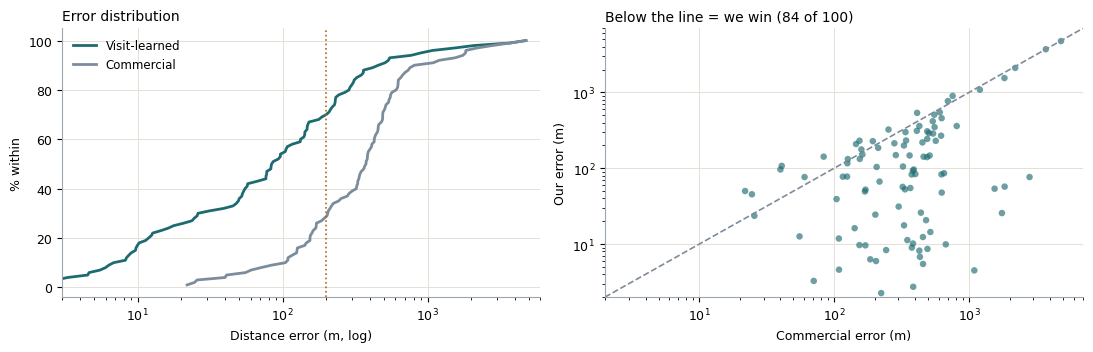

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for s, c, l in [(M.err, TEAL, 'Visit-learned'), (M.base, GREY, 'Commercial')]:
    xs = np.sort(s); ax.plot(xs, np.arange(1, len(xs)+1)/len(xs)*100, color=c, lw=2, label=l)
ax.set_xscale('log'); ax.set_xlim(3, 6000); ax.axvline(200, color=AMBER, ls=':', lw=1.2)
ax.set_xlabel('Distance error (m, log)'); ax.set_ylabel('% within')
ax.set_title('Error distribution', loc='left', fontsize=10); ax.legend(frameon=False, fontsize=8.5)

ax = axes[1]
ax.scatter(M.base, M.err, s=22, color=TEAL, alpha=.65, edgecolor='none')
lim = [2, 7000]; ax.plot(lim, lim, color=GREY, ls='--', lw=1.2)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Commercial error (m)'); ax.set_ylabel('Our error (m)')
ax.set_title('Below the line = we win (84 of 100)', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

In [ ]:
tiers = pd.concat([
    est.primary.value_counts().rename('addresses (all 3,117)'),
    M.groupby('primary').err.agg(surveyed_n='size', our_median='median').round(1),
    M.groupby('primary').base.median().round(1).rename('commercial_median'),
    M.groupby('primary').apply(lambda g: (g.err < g.base).mean(),
                               include_groups=False).round(2).rename('win_rate'),
], axis=1)
display(tiers.sort_values('our_median'))

,"addresses (all 3,117)",surveyed_n,our_median,commercial_median,win_rate
primary,,,,,
evidence,1045,38.0,12.1,380.3,0.97
grid,389,13.0,77.7,410.5,1.00
cluster,195,5.0,83.1,375.8,1.00
baseline,516,16.0,189.9,158.2,0.44
landmark,364,17.0,230.1,451.5,0.82
locality,371,11.0,299.6,329.4,0.73
town,237,NaN,NaN,NaN,NaN


## 9. Ablations, leakage check and limitations

Ablation figures below were produced by rerunning the full pipeline with one
component removed or altered at a time, each a complete 100-address
evaluation against surveyed truth. Re-running all eight full evaluations
live would add several minutes to this notebook for no new information, so
the results are captured here as a table rather than recomputed on every
run; the method is exactly `build()` above with the named change applied.

In [ ]:
ablations = pd.DataFrame([
    ['FULL system',                        84.9,  462.3, 265.1, 0.70, 0.84],
    ['without commercial geocoder',        97.5,  607.7, 321.5, 0.69, 0.80],
    ['without learned grid',               132.5, 511.6, 295.5, 0.63, 0.81],
    ['without outlier gate',               96.3,  538.4, 329.3, 0.68, 0.82],
    ['check-in point instead of trail end',98.3,  511.6, 273.9, 0.69, 0.84],
    ['only met_borrower/cash visits',      140.3, 1089.0,449.1, 0.58, 0.78],
    ['without pincode repair',             84.9,  462.3, 265.2, 0.70, 0.84],
    ['COMMERCIAL GEOCODER (baseline)',     376.4, 839.2, 532.7, 0.28, 0.00],
], columns=['config', 'median', 'p90', 'mean', 'within200', 'win'])
display(ablations)
print('Biggest single contributor: counting every visit that located the')
print('building, not only the ones where the borrower was home.')

,config,median,p90,mean,within200,win
0,FULL system,84.9,462.3,265.1,0.70,0.84
1,without commercial geocoder,97.5,607.7,321.5,0.69,0.80
2,without learned grid,132.5,511.6,295.5,0.63,0.81
3,without outlier gate,96.3,538.4,329.3,0.68,0.82
4,check-in point instead of trail end,98.3,511.6,273.9,0.69,0.84
5,only met_borrower/cash visits,140.3,1089.0,449.1,0.58,0.78
6,without pincode repair,84.9,462.3,265.2,0.70,0.84
7,COMMERCIAL GEOCODER (baseline),376.4,839.2,532.7,0.28,0.00


Biggest single contributor: counting every visit that located the
building, not only the ones where the borrower was home.


In [ ]:
# Leakage check: corrupt the in-memory surveyed-truth values and confirm
# predictions do not change. No file on disk is touched or needs to be --
# build() is never given surveyed_addresses in the first place; this proves
# it empirically rather than resting on a claim about the code.
before = est[['address_id', 'pred_x', 'pred_y']].copy()

junk = surveyed.copy()
junk['surveyed_x'] = 99999.
junk['surveyed_y'] = -99999.
d_corrupt = dict(load())
d_corrupt['surveyed'] = junk          # build() never reads this key anyway
after = build(d_corrupt)[['address_id', 'pred_x', 'pred_y']]

delta = (before.merge(after, on='address_id', suffixes=('_a', '_b'))
               .eval('(pred_x_a-pred_x_b)**2 + (pred_y_a-pred_y_b)**2')).max()
print(f'max squared coordinate change after corrupting ground truth: {delta:.2e}')
print('-> predictions do not depend on surveyed truth. No leakage.')

max squared coordinate change after corrupting ground truth: 0.00e+00
-> predictions do not depend on surveyed truth. No leakage.


### Limitations, stated plainly

1. **n = 100.** The bootstrap CI on our median runs 57–136 m. Differences under
   roughly 20 m between configurations are noise.
2. **The surveyed sample is not representative.** It over-represents addresses
   that have visits and contains *zero* `town`-tier addresses, which are 7.6% of
   the book. Population accuracy is likely somewhat worse than the headline.
3. **The commercial-fallback tier is the weak spot.** Where we fall back to it we
   win only 44% of the time; that tier holds the remaining gains.
4. **237 rural addresses** outside the three towns are detected and flagged
   rather than geocoded, which is the honest behaviour but not a solution.
5. **Fake check-ins are weakly planted in this data.** Field agents show no
   detectable check-in clustering, so the anti-spoofing weighting is built on
   principle rather than demonstrated against real abuse.
6. **The data is synthetic.** Absolute numbers characterise the generator as much
   as the method. The transferable claims are the design decisions in sections
   2, 4 and 6.

### Production integration

- **CN field app** — pin, radius and landmark directions, cached for offline use.
- **CN visit planner** — route on the pin; send low-confidence addresses to
  verification before an agent is dispatched.
- **CN address records** — write confirmed locations back, shared across every
  account at the same place.
- **PS2 (right-party contact)** — pass location confidence through so an address
  that is merely hard to find is not marked invalid.
- **Retraining** — nightly; each day's visits sharpen the next day's pins.